## 1. Imports and Config

In [1]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    ConfusionMatrixDisplay
)
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

artifacts = joblib.load('eda_artifacts.pkl')
df = artifacts['df']
num_features = artifacts['num_features']
iso_anomaly = artifacts['iso_anomaly']

print('Data loaded from EDA.')

Data loaded from EDA.


---
## 2. Data Preparation

In [2]:
df_model = df[num_features + ['Type', 'Target']].copy()
df_model = pd.get_dummies(df_model, columns=['Type'], drop_first=False)

feature_cols = [c for c in df_model.columns if c != 'Target']
X_all = df_model[feature_cols].values
y_all = df_model['Target'].values

X_train_calib, X_test, y_train_calib, y_test = train_test_split(
    X_all, y_all, test_size=0.15, random_state=17, stratify=y_all
)
X_train, X_calib, y_train, y_calib = train_test_split(
    X_train_calib, y_train_calib, test_size=0.176, random_state=17, stratify=y_train_calib
)
# 0.176 * 0.85 ≈ 0.15  ->  train≈70%, calib≈15%, test≈15%

scaler = StandardScaler()
X_train_sc       = scaler.fit_transform(X_train)
X_calib_sc       = scaler.transform(X_calib)
X_test_sc        = scaler.transform(X_test)
X_train_calib_sc = scaler.transform(X_train_calib)

print(f'Train: {X_train.shape[0]} samples')
print(f'Calib: {X_calib.shape[0]} samples')
print(f'Test:  {X_test.shape[0]} samples')
print(f'Train failures: {y_train.sum()} ({y_train.mean()*100:.1f}%)')
print(f'Calib failures: {y_calib.sum()} ({y_calib.mean()*100:.1f}%)')
print(f'Test  failures: {y_test.sum()}  ({y_test.mean()*100:.1f}%)')
print(f'\nFeatures: {len(feature_cols)}\n{feature_cols}')

Train: 7004 samples
Calib: 1496 samples
Test:  1500 samples
Train failures: 237 (3.4%)
Calib failures: 51 (3.4%)
Test  failures: 51  (3.4%)

Features: 8
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']


---
## 3. Training and Basic Evaluation

In [3]:
svm = SVC(
    kernel='rbf',
    C=10,
    gamma='scale',
    class_weight='balanced',
    probability=True,
    random_state=18
)
svm.fit(X_train_sc, y_train)

y_pred  = svm.predict(X_test_sc)
y_proba = svm.predict_proba(X_test_sc)[:, 1]

print('- Classification Report -')
print(classification_report(y_test, y_pred, target_names=['No Failure', 'Failure']))

roc_auc  = roc_auc_score(y_test, y_proba)
avg_prec = average_precision_score(y_test, y_proba)
print(f'ROC-AUC: {roc_auc:.4f}')
print(f'Average Precision: {avg_prec:.4f}')

- Classification Report -
              precision    recall  f1-score   support

  No Failure       1.00      0.94      0.97      1449
     Failure       0.36      0.90      0.51        51

    accuracy                           0.94      1500
   macro avg       0.68      0.92      0.74      1500
weighted avg       0.97      0.94      0.95      1500

ROC-AUC: 0.9655
Average Precision: 0.6696


---
## 4. Confusion Matrix

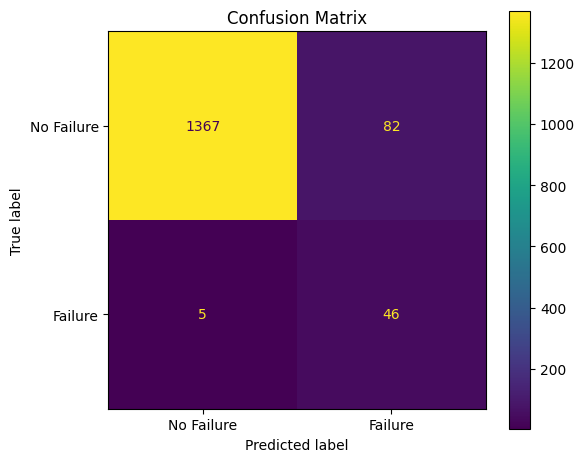


False Alarm Rate: 0.057
Miss Rate: 0.098


In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No Failure', 'Failure'])
disp.plot(ax=ax)
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'\nFalse Alarm Rate: {fp/(fp+tn):.3f}')
print(f'Miss Rate: {fn/(fn+tp):.3f}')

---
## 5. ROC Curve and Precision-Recall Curve

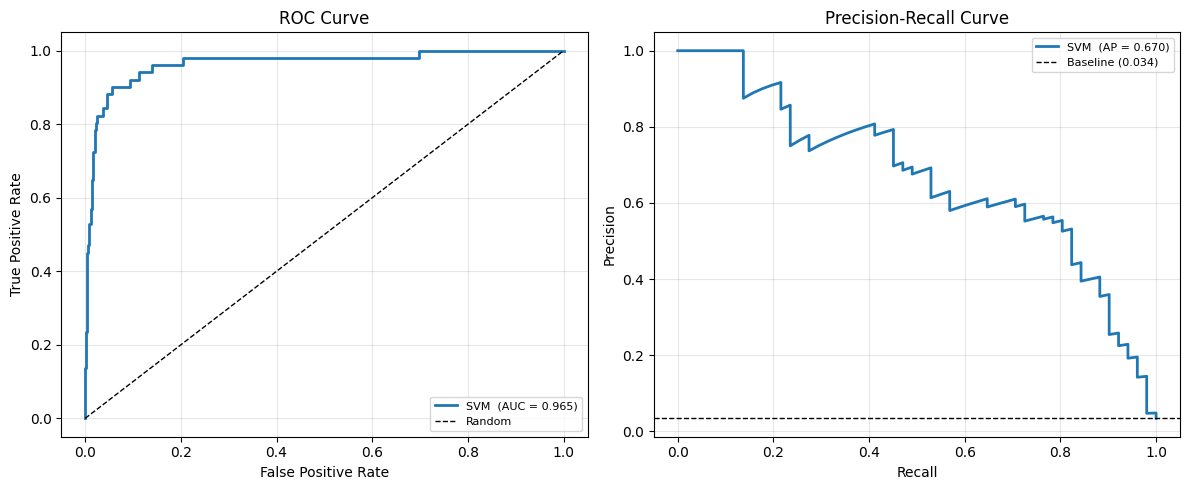

In [5]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
prec, rec, _ = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
ax = axes[0]
ax.plot(fpr, tpr, lw=2, label=f'SVM  (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Precision-Recall
ax = axes[1]
ax.plot(rec, prec, lw=2, label=f'SVM  (AP = {avg_prec:.3f})')
baseline = y_test.mean()
ax.axhline(baseline, color='k', linestyle='--', lw=1, label=f'Baseline ({baseline:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 6. Support Vectors

In [7]:
n_sv = svm.n_support_
print(f'Number of support vectors per class:')
print(f'No Failure: {n_sv[0]}')
print(f'Failure: {n_sv[1]}')
print(f'Total: {n_sv.sum()} / {X_train_sc.shape[0]} ({n_sv.sum()/X_train_sc.shape[0]*100:.1f}% of training set)')

Number of support vectors per class:
No Failure: 1099
Failure: 92
Total: 1191 / 7004 (17.0% of training set)


---
## 7. Cross-validation (Stratified 5-Fold)

In [ ]:
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(
        kernel='rbf', C=10, gamma='scale',
        class_weight='balanced', probability=True, random_state=18
    ))
])

cv_results = cross_validate(
    svm_pipeline, X_all, y_all, cv=cv,
    scoring=['roc_auc', 'average_precision', 'f1', 'recall', 'precision'],
    return_train_score=False
)

metrics = {
    'ROC-AUC': cv_results['test_roc_auc'],
    'Avg Precision': cv_results['test_average_precision'],
    'F1 (Failure)': cv_results['test_f1'],
    'Recall (Failure)': cv_results['test_recall'],
    'Precision (Failure)': cv_results['test_precision'],
}

print('- Cross-Validation Results (5-Fold) -')
print(f'{"Metric":<23} {"Mean":>8} {"Std":>8} {"Min":>8} {"Max":>8}')
print('-' * 60)
for name, vals in metrics.items():
    print(f'{name:<25} {vals.mean():>8.4f} {vals.std():>8.4f} {vals.min():>8.4f} {vals.max():>8.4f}')

- Cross-Validation Results (5-Fold) -
Metric                      Mean      Std      Min      Max
------------------------------------------------------------
ROC-AUC                     0.9576   0.0147   0.9428   0.9780
Avg Precision               0.6452   0.0436   0.5870   0.6980
F1 (Failure)                0.4858   0.0319   0.4412   0.5362
Recall (Failure)            0.8730   0.0575   0.7941   0.9412
Precision (Failure)         0.3379   0.0306   0.2941   0.3772
